<a href="https://colab.research.google.com/github/HafidzSetyawannn/Advanced-Mathematics-Assignment-05/blob/main/Tugas_5_Advanced_Mathematics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Soal 1 – Konvergensi dan Divergensi Lelaran Titik-Tetap

### Teori singkat
Persamaan $f(x)=0$ disusun ulang menjadi $x=g(x)$, lalu dilelar dengan

$$x_{r+1}=g(x_r)$$

Misalkan $s$ adalah akar sejati ($s=g(s)$). Galat tiap lelaran $e_r = x_r - s$ memenuhi, untuk $x_r$ dekat $s$,

$$e_{r+1}\approx g'(s)\,e_r$$

sehingga perilaku lelaran ditentukan oleh nilai $g'(s)$ (secara praktis, $g'(x)$ di sekitar akar):

| Nilai $g'(s)$ | Perilaku lelaran |
|---|---|
| $0 < g'(s) < 1$ | **Konvergen monoton** |
| $-1 < g'(s) < 0$ | **Konvergen berosilasi** |
| $g'(s) > 1$ | **Divergen monoton** |
| $g'(s) < -1$ | **Divergen berosilasi** |

**Syarat cukup konvergen:** $|g'(x)|<1$ untuk semua $x$ di selang yang memuat akar dan tebakan awal $x_0$. Makin kecil $|g'(s)|$, makin cepat konvergensinya.

### Percobaan
Kita pakai contoh dari: $f(x)=x^2-2x-3=0$ (akar sejati $x=3$ dan $x=-1$) dengan tebakan awal $x_0=4$ dan tiga bentuk $g(x)$ yang berbeda.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def titik_tetap(g, x0, eps=1e-6, nmaks=30):
    """Lelaran titik-tetap x_{r+1} = g(x_r). Mengembalikan riwayat nilai x dan status konvergensi."""
    xs = [x0]
    x = x0
    for i in range(nmaks):
        try:
            x_baru = g(x)
        except (ValueError, ZeroDivisionError, OverflowError):
            return xs, False
        xs.append(x_baru)
        if abs(x_baru - x) < eps:
            return xs, True
        x = x_baru
    return xs, False

def tabel(xs):
    selisih = [np.nan] + [abs(xs[i+1]-xs[i]) for i in range(len(xs)-1)]
    return pd.DataFrame({"r": range(len(xs)), "x_r": xs, "|x_r+1 - x_r|": selisih}).set_index("r")

In [ ]:
g_a  = lambda x: np.sqrt(2*x + 3)
g_b  = lambda x: 3/(x - 2)
g_c  = lambda x: (x**2 - 3)/2

dg_a = lambda x: 1/np.sqrt(2*x + 3)
dg_b = lambda x: -3/(x - 2)**2
dg_c = lambda x: x

kasus = [("(a) g(x)=sqrt(2x+3)", g_a, dg_a, 3.0),
         ("(b) g(x)=3/(x-2)",    g_b, dg_b, -1.0),
         ("(c) g(x)=(x^2-3)/2",  g_c, dg_c, 3.0)]

hasil = {}
for nama, g, dg, akar in kasus:
    xs, ok = titik_tetap(g, 4.0)
    hasil[nama] = xs
    print(f"{nama}:  akar yang dituju = {akar},  g'(akar) = {dg(akar):+.3f},  "
          f"{'KONVERGEN' if ok else 'DIVERGEN'}  ({len(xs)-1} lelaran)")
    print(tabel(xs).head(6).to_string(float_format=lambda v: f"{v:.6f}"))
    print()

(a) g(x)=sqrt(2x+3):  akar yang dituju = 3.0,  g'(akar) = +0.333,  KONVERGEN  (14 lelaran)
       x_r  |x_r+1 - x_r|
r                        
0 4.000000            NaN
1 3.316625       0.683375
2 3.103748       0.212877
3 3.034385       0.069362
4 3.011440       0.022945
5 3.003811       0.007629

(b) g(x)=3/(x-2):  akar yang dituju = -1.0,  g'(akar) = -0.333,  KONVERGEN  (17 lelaran)
        x_r  |x_r+1 - x_r|
r                         
0  4.000000            NaN
1  1.500000       2.500000
2 -6.000000       7.500000
3 -0.375000       5.625000
4 -1.263158       0.888158
5 -0.919355       0.343803

(c) g(x)=(x^2-3)/2:  akar yang dituju = 3.0,  g'(akar) = +3.000,  DIVERGEN  (10 lelaran)
               x_r    |x_r+1 - x_r|
r                                  
0         4.000000              NaN
1         6.500000         2.500000
2        19.625000        13.125000
3       191.070312       171.445312
4     18252.432159     18061.361847
5 166575638.367185 166557385.935025



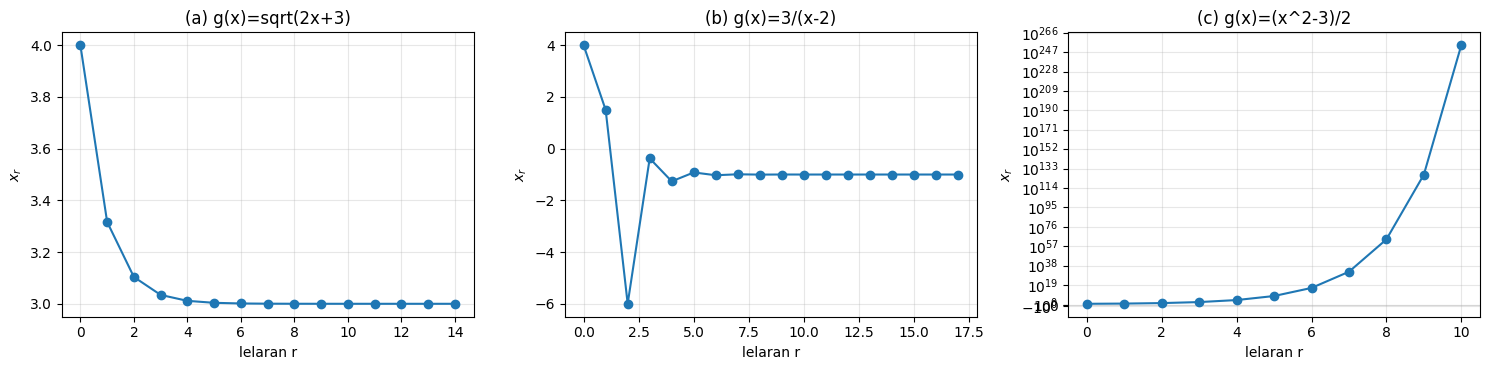

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (nama, xs) in zip(ax, hasil.items()):
    xs = np.array(xs, dtype=float)
    a.plot(range(len(xs)), xs, "o-")
    a.set_title(nama); a.set_xlabel("lelaran r"); a.set_ylabel("$x_r$"); a.grid(alpha=.3)
    if np.nanmax(np.abs(xs)) > 1e3:
        a.set_yscale("symlog")
plt.tight_layout(); plt.show()

### Hasil dan analisis

| Bentuk $g(x)$ | $g'(s)$ di akar yang dituju | Perilaku |
|---|---|---|
| (a) $\sqrt{2x+3}$ | $g'(3)=1/3$ | $0<g'<1$ → **konvergen monoton** ke $x=3$ |
| (b) $3/(x-2)$ | $g'(-1)=-1/3$ | $-1<g'<0$ → **konvergen berosilasi** ke $x=-1$ |
| (c) $(x^2-3)/2$ | $g'(3)=3$ | $g'>1$ → **divergen monoton** (nilai $x_r$ membesar tanpa batas) |

Persamaan yang sama bisa konvergen atau divergen, **tergantung cara menyusun $g(x)$** dan **tebakan awal $x_0$**. Pada (b), akar $x=3$ tidak bisa dicapai karena $g'(3)=-3$ ($|g'|>1$); lelaran justru "lari" ke akar lain, $x=-1$.

### Cara mengatasi divergensi
1. **Susun ulang $g(x)$** sehingga $|g'(x)|<1$ di sekitar akar (contoh: ganti (c) dengan (a)).
2. **Ganti tebakan awal $x_0$** agar berada di daerah $|g'(x)|<1$.
3. **Relaksasi (pembobotan):** $x_{r+1}=(1-w)x_r+w\,g(x_r)$ dengan $w$ dipilih agar $|1-w+w\,g'(s)|<1$.
4. **Pakai metode lain**, misalnya Newton-Raphson (yang pada dasarnya adalah titik-tetap dengan $g(x)=x-f(x)/f'(x)$ sehingga $g'(s)=0$), atau metode tertutup (bagidua/regula-falsi) yang selalu konvergen.
5. **Batasi jumlah lelaran** ($N_{maks}$) agar program tidak berjalan tanpa henti (seperti Program 3.6 pada materi).

Berikut demonstrasi cara 1, 3, dan 4 untuk kasus (c) yang divergen.

In [ ]:
f  = lambda x: x**2 - 2*x - 3
df = lambda x: 2*x - 2

w = -0.5
g_relaks = lambda x: (1 - w)*x + w*g_c(x)

g_newton = lambda x: x - f(x)/df(x)

perbaikan = {"(c) asli (divergen)": g_c,
             "Cara 1: ganti g(x) = sqrt(2x+3)": g_a,
             "Cara 3: relaksasi w = -0.5": g_relaks,
             "Cara 4: Newton-Raphson": g_newton}

for nama, g in perbaikan.items():
    xs, ok = titik_tetap(g, 4.0)
    hasil_x = f"x = {xs[-1]:.6f}" if ok else "x membesar tanpa batas"
    print(f"{nama:38s} -> {'konvergen' if ok else 'DIVERGEN '}  {hasil_x}  ({len(xs)-1} lelaran)")

(c) asli (divergen)                    -> DIVERGEN   x membesar tanpa batas  (10 lelaran)
Cara 1: ganti g(x) = sqrt(2x+3)        -> konvergen  x = 3.000000  (14 lelaran)
Cara 3: relaksasi w = -0.5             -> konvergen  x = 3.000000  (5 lelaran)
Cara 4: Newton-Raphson                 -> konvergen  x = 3.000000  (5 lelaran)


## Soal 2 – Newton-Raphson untuk $4x^3-15x^2+17x-6=0$, $x_0=3$

### Rumus
$$x_{r+1}=x_r-\frac{f(x_r)}{f'(x_r)},\qquad f(x)=4x^3-15x^2+17x-6,\quad f'(x)=12x^2-30x+17$$

Lelaran berhenti jika $|x_{r+1}-x_r|<\varepsilon$ (di sini $\varepsilon=10^{-6}$).

In [ ]:
def f(x):  return 4*x**3 - 15*x**2 + 17*x - 6
def df(x): return 12*x**2 - 30*x + 17

def newton_raphson(f, df, x0, eps=1e-6, nmaks=50):
    baris = []
    x = x0
    for r in range(nmaks):
        if df(x) == 0:
            print("f'(x)=0, lelaran dihentikan"); break
        x_baru = x - f(x)/df(x)
        baris.append((r, x, f(x), df(x), x_baru, abs(x_baru - x)))
        if abs(x_baru - x) < eps:
            x = x_baru; break
        x = x_baru
    tab = pd.DataFrame(baris, columns=["r", "x_r", "f(x_r)", "f'(x_r)", "x_r+1", "|x_r+1 - x_r|"]).set_index("r")
    return x, tab

akar, tab = newton_raphson(f, df, x0=3.0)
pd.set_option("display.float_format", lambda v: f"{v:.8f}")
print(tab.to_string())
print(f"\nHampiran akar = {akar:.6f}   (f(akar) = {f(akar):.2e})")
print(f"Jumlah lelaran = {len(tab)}")

         x_r      f(x_r)     f'(x_r)      x_r+1  |x_r+1 - x_r|
r                                                             
0 3.00000000 18.00000000 35.00000000 2.48571429     0.51428571
1 2.48571429  5.01019242 16.57387755 2.18341976     0.30229452
2 2.18341976  1.24456712  8.70526943 2.04045266     0.14296710
3 2.04045266  0.21725587  5.74778495 2.00265447     0.03779819
4 2.00265447  0.01333586  5.04786507 2.00001259     0.00264188
5 2.00001259  0.00006296  5.00022667 2.00000000     0.00001259
6 2.00000000  0.00000000  5.00000001 2.00000000     0.00000000

Hampiran akar = 2.000000   (f(akar) = 0.00e+00)
Jumlah lelaran = 7


### Verifikasi
Persamaan dapat difaktorkan: $4x^3-15x^2+17x-6=(x-2)(4x-3)(x-1)$, sehingga akar sejatinya adalah $x=2,\ x=1,\ x=\tfrac34$. Dengan $x_0=3$, Newton-Raphson konvergen ke akar $x=2$ (akar terdekat dari tebakan awal).

In [ ]:
print("Akar sejati (numpy.roots):", np.sort(np.roots([4, -15, 17, -6])))
print("Galat |x - 2|            :", abs(akar - 2))

e = np.abs(np.append(tab["x_r"].values, tab["x_r+1"].values[-1]) - 2)
print("\nRasio e_{r+1}/e_r^2:")
for i in range(len(e)-1):
    if e[i] > 1e-7:
        print(f"  r={i}: {e[i+1]/e[i]**2:.4f}")

Akar sejati (numpy.roots): [0.75 1.   2.  ]
Galat |x - 2|            : 0.0

Rasio e_{r+1}/e_r^2:
  r=0: 0.4857
  r=1: 0.7775
  r=2: 1.2024
  r=3: 1.6221
  r=4: 1.7871
  r=5: 1.7999


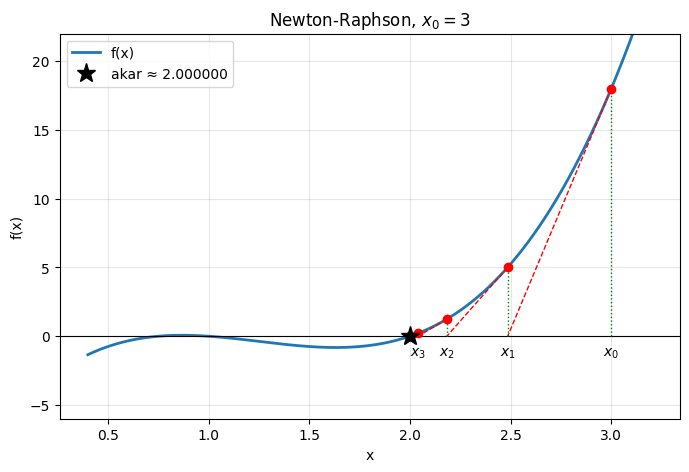

In [ ]:
xx = np.linspace(0.4, 3.2, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, f(xx), label="f(x)", lw=2)
plt.axhline(0, color="k", lw=.8)
for r, row in tab.iterrows():
    x0_, y0_, x1_ = row["x_r"], row["f(x_r)"], row["x_r+1"]
    plt.plot([x0_, x1_], [y0_, 0], "r--", lw=1)
    plt.plot([x0_, x0_], [0, y0_], "g:", lw=1)
    plt.plot(x0_, y0_, "ro")
    if r < 4: plt.annotate(f"$x_{r}$", (x0_, 0), textcoords="offset points", xytext=(0, -14), ha="center")
plt.plot(akar, 0, "k*", ms=14, label=f"akar ≈ {akar:.6f}")
plt.ylim(-6, 22); plt.xlabel("x"); plt.ylabel("f(x)")
plt.title("Newton-Raphson, $x_0=3$"); plt.legend(); plt.grid(alpha=.3); plt.show()

### Kesimpulan
- Dengan $x_0=3$, Newton-Raphson konvergen ke **$x = 2$** dalam 7 lelaran (r = 0 sampai 6) dengan $\varepsilon=10^{-6}$, sesuai akar sejati hasil faktorisasi.
- Konvergensinya **kuadratik**: jumlah digit benar kira-kira berlipat dua tiap lelaran, jauh lebih cepat daripada metode bagidua (±20 lelaran untuk ketelitian yang sama) maupun titik-tetap biasa.
- Akar lain ($x=1$ dan $x=0{,}75$) bisa diperoleh dengan mengganti $x_0$, misalnya $x_0=1{,}2$ atau $x_0=0{,}5$.
- Kelemahan: metode ini membutuhkan $f'(x)$ dan gagal jika $f'(x_r)\approx 0$ atau tebakan awal terlalu jauh dari akar.

In [ ]:
for x0 in [0.5, 1.2, 3.0]:
    a, t = newton_raphson(f, df, x0)
    print(f"x0 = {x0}: akar = {a:.6f} ({len(t)} lelaran)")

x0 = 0.5: akar = 0.750000 (6 lelaran)
x0 = 1.2: akar = 1.000000 (5 lelaran)
x0 = 3.0: akar = 2.000000 (7 lelaran)
